# Этап 6. Модель: от чего зависит доход региона

**Вопрос заказчика:** какие факторы объясняют различия в доходах населения между регионами и можно ли по ним предсказать доход?
**Связь с гипотезами:** H1 — доход сильнее связан с экономикой и занятостью, чем с медициной.

## Оглавление
1. [Настройка и загрузка](#setup)
2. [Постановка: что предсказываем и чем](#design)
3. [Мультиколлинеарность](#vif)
4. [Сравнение моделей](#compare)
5. [Прогноз на 2022–2024 гг.](#forecast)
6. [Коэффициенты и их надёжность (H1)](#coefs)
7. [Эластичность: как богатство региона доходит до людей](#elasticity)
8. [Кто получает больше или меньше, чем «заработал» регион](#residuals)
9. [Выводы этапа](#summary)

<a id="setup"></a>
## 1. Настройка и загрузка

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import LeaveOneGroupOut

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b4b2a9", "grid.color": "#e6e4dd",
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

BLUE, ORANGE = "#2a78d6", "#eb6834"
GRAY, LIGHT, INK, MUTED = "#b4b2a9", "#d9d7cf", "#0b0b0b", "#52514e"
SEED = 42

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
IMAGES = ROOT / "images"
IMAGES.mkdir(exist_ok=True)

units = pd.read_csv(DATA / "panel_units_clean.csv")
SHORT = {"Южно-Казахстанская (Туркестанская + Шымкент)": "ЮКО (Туркестанская + Шымкент)",
         "Восточно-Казахстанская + Абай": "ВКО + Абай", "Западно-Казахстанская": "ЗКО",
         "Северо-Казахстанская": "СКО"}
units["label"] = units.unit_name.replace(SHORT)
print(f"Панель: {units.unit_id.nunique()} единиц × {units.year.nunique()} лет = {len(units)} наблюдений")

Панель: 16 единиц × 10 лет = 160 наблюдений


<a id="design"></a>
## 2. Постановка: что предсказываем и чем

**Целевая переменная** — доход на душу **относительно среднего по регионам в том же году**, в логарифмах:
`y = log(доход) − среднее log(доход) за год`.

Почему так, а не просто доход в тенге: за 10 лет все доходы выросли примерно в 3 раза из-за инфляции. Модель на «сырых» тенге в первую очередь выучит год, а не различия между регионами. Относительная шкала убирает общий рост цен, и `y = 0,10` читается как «доход примерно на 10% выше типичного региона». Так же преобразуем факторы. Ещё один плюс: модель не привязана к конкретным годам и может предсказывать годы, которых не видела.

**Факторы** (по итогам EDA):

| Фактор | Преобразование | Зачем |
|---|---|---|
| ВРП на душу | относительный логарифм | размер экономики региона |
| Врачи на 10 тыс. | относительный логарифм | медицина (H1) |
| Ввод жилья на 1000 чел. | относительный логарифм | развитие, стройка |
| Неформальная занятость | отклонение от среднего, п. п. | качество занятости (H1) |

**Не используем:**
- зарплату — она сама часть дохода, модель стала бы тавтологией;
- инвестиции вместе с ВРП — мультиколлинеарность (раздел 3);
- бедность, миграцию, продолжительность жизни — это следствия дохода, а не причины;
- безработицу — она не различается между регионами (EDA).

In [2]:
def rel_log(col):
    log = np.log(units[col])
    return log - log.groupby(units.year).transform("mean")

def rel(col):
    return units[col] - units.groupby("year")[col].transform("mean")

D = pd.DataFrame({
    "y": rel_log("income_pc"),
    "ВРП": rel_log("grp_pc"),
    "Инвестиции": rel_log("investments_pc"),
    "Врачи": rel_log("doctors_per10k"),
    "Жильё": rel_log("housing_m2_per1000"),
    "Неформальная занятость": rel("informal_share"),
    "year": units.year,
    "unit": units.unit_id,
    "label": units.label,
})
year_mean_log = np.log(units.income_pc).groupby(units.year).mean()

FEATURE_SETS = {
    "только ВРП": ["ВРП"],
    "социальные факторы": ["Врачи", "Жильё", "Неформальная занятость"],
    "ВРП + социальные": ["ВРП", "Врачи", "Жильё", "Неформальная занятость"],
}
D.describe().loc[["mean", "std", "min", "max"]].round(3)

,y,ВРП,Инвестиции,Врачи,Жильё,Неформальная занятость,year,unit
mean,0.000,-0.000,0.000,0.000,0.000,-0.000,2019.500,41.500
std,0.318,0.583,0.652,0.322,0.580,7.625,2.881,19.289
min,-0.654,-0.921,-1.073,-0.448,-1.025,-16.369,2015.000,11.000
max,0.729,1.442,2.477,0.931,1.617,16.644,2024.000,75.000


<a id="vif"></a>
## 3. Мультиколлинеарность

**VIF** (variance inflation factor) показывает, насколько фактор дублируется другими. VIF > 5 — коэффициенты становятся неустойчивыми.

In [3]:
def vif(X: pd.DataFrame) -> pd.Series:
    return pd.Series({c: 1 / (1 - LinearRegression().fit(X.drop(columns=c), X[c]).score(X.drop(columns=c), X[c]))
                      for c in X}).round(2)

pd.DataFrame({
    "с инвестициями": vif(D[["ВРП", "Инвестиции", "Врачи", "Жильё", "Неформальная занятость"]]),
    "без инвестиций": vif(D[["ВРП", "Врачи", "Жильё", "Неформальная занятость"]]),
})

,с инвестициями,без инвестиций
ВРП,5.77,1.80
Врачи,2.15,1.38
Жильё,2.00,1.80
Инвестиции,5.29,NaN
Неформальная занятость,1.34,1.32


**Вывод:** вместе ВРП и инвестиции дают VIF 5,3–5,8 — они дублируют друг друга. Без инвестиций все VIF ниже 2. Оставляем ВРП: он сильнее связан с доходом (EDA: ρ = 0,95 против 0,81).

<a id="compare"></a>
## 4. Сравнение моделей

Сравниваем линейную регрессию и случайный лес (Random Forest) на трёх наборах факторов. Базовая модель для сравнения — «все регионы одинаковы» (предсказываем 0).

Две схемы проверки — модель всегда оценивается на данных, которых не видела:
- **прогноз во времени**: обучаем на 2015–2021 гг., проверяем на 2022–2024 гг.;
- **новый регион**: обучаем на 15 единицах, проверяем на 16-й, и так для каждой (leave-one-region-out). Это строже: модель не может «запомнить» регион.

Метрики: **R²** (доля объяснённого разброса, 1 — идеально, 0 — не лучше базовой) и **MAE** — средняя ошибка в логарифмических пунктах (0,08 ≈ ошибка 8%).

In [4]:
MODELS = {
    "Линейная регрессия": lambda: LinearRegression(),
    "Random Forest": lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=SEED),
}
train, test = D.year <= 2021, D.year >= 2022

rows = [{"набор факторов": "базовая (среднее)", "модель": "—",
         "R² прогноз 2022–24": r2_score(D.y[test], np.zeros(test.sum())),
         "MAE прогноз 2022–24": mean_absolute_error(D.y[test], np.zeros(test.sum())),
         "R² новый регион": r2_score(D.y, np.zeros(len(D))),
         "MAE новый регион": mean_absolute_error(D.y, np.zeros(len(D)))}]

for set_name, cols in FEATURE_SETS.items():
    for model_name, make in MODELS.items():
        oot = make().fit(D.loc[train, cols], D.y[train]).predict(D.loc[test, cols])
        loro = np.zeros(len(D))
        for tr_idx, te_idx in LeaveOneGroupOut().split(D, groups=D.unit):
            loro[te_idx] = make().fit(D.iloc[tr_idx][cols], D.y.iloc[tr_idx]).predict(D.iloc[te_idx][cols])
        rows.append({"набор факторов": set_name, "модель": model_name,
                     "R² прогноз 2022–24": r2_score(D.y[test], oot),
                     "MAE прогноз 2022–24": mean_absolute_error(D.y[test], oot),
                     "R² новый регион": r2_score(D.y, loro),
                     "MAE новый регион": mean_absolute_error(D.y, loro)})

comparison = pd.DataFrame(rows).round(3)
comparison

,набор факторов,модель,R² прогноз 2022–24,MAE прогноз 2022–24,R² новый регион,MAE новый регион
0,базовая (среднее),—,0.000,0.228,0.000,0.248
1,только ВРП,Линейная регрессия,0.888,0.075,0.904,0.078
2,только ВРП,Random Forest,0.874,0.077,0.890,0.086
3,социальные факторы,Линейная регрессия,0.345,0.187,0.191,0.222
4,социальные факторы,Random Forest,0.072,0.185,-0.044,0.263
5,ВРП + социальные,Линейная регрессия,0.890,0.077,0.866,0.093
6,ВРП + социальные,Random Forest,0.904,0.067,0.813,0.106


**Вывод:**
- **Один ВРП объясняет почти всё:** R² ≈ 0,89–0,90 и в прогнозе на новые годы, и на новых регионах. Средняя ошибка — 7–8%.
- **Добавление социальных факторов не улучшает модель**, а на новых регионах даже ухудшает (R² 0,90 → 0,87): лишние факторы подстраиваются под шум обучающих данных — это переобучение.
- **Социальные факторы без ВРП объясняют мало**: R² 0,19–0,35, ошибка около 19–22%.
- **Random Forest не лучше линейной регрессии.** В прогнозе на новые годы он немного точнее (R² 0,90 против 0,89), но на новых регионах заметно хуже (0,81 против 0,87). При 160 наблюдениях и почти линейной связи «лес» не находит ничего, чего не видит прямая, зато сильнее подстраивается под знакомые регионы.

**Итоговая модель: линейная регрессия на ВРП** — самая простая и самая точная.

<a id="forecast"></a>
## 5. Прогноз на 2022–2024 гг.

Обучаем итоговую модель на 2015–2021 гг. и предсказываем доход каждой единицы на 2022–2024 гг. Чтобы перевести ответ в тенге, прибавляем средний логарифм дохода за год (его модель не прогнозирует — это общий уровень цен и доходов в стране).

Прогноз 2022–2024: R² = 0.888, MAE = 15.9 тыс. тенге, средняя ошибка 7.6%


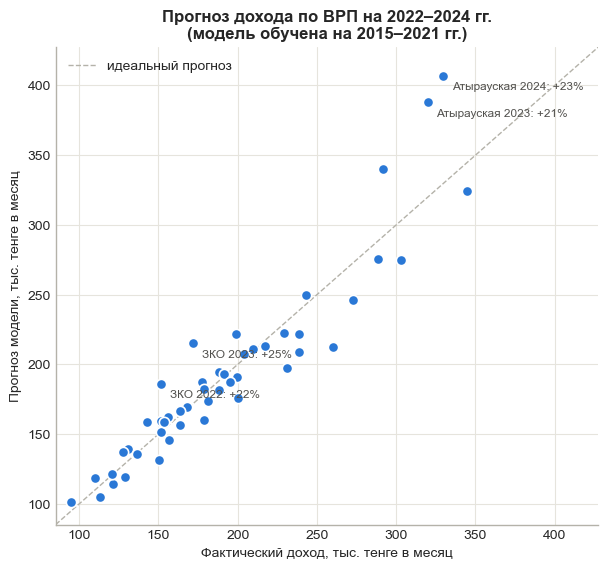

In [5]:
final_cols = FEATURE_SETS["только ВРП"]
final = LinearRegression().fit(D.loc[train, final_cols], D.y[train])

fc = D.loc[test, ["label", "year", "y"]].copy()
fc["прогноз_rel"] = final.predict(D.loc[test, final_cols])
fc["доход"] = np.exp(fc.y + year_mean_log.loc[fc.year].values)
fc["прогноз"] = np.exp(fc["прогноз_rel"] + year_mean_log.loc[fc.year].values)
fc["ошибка, %"] = (fc["прогноз"] / fc["доход"] - 1) * 100

mae_tenge = (fc["прогноз"] - fc["доход"]).abs().mean()
mape = fc["ошибка, %"].abs().mean()
print(f"Прогноз 2022–2024: R² = {r2_score(fc.y, fc['прогноз_rel']):.3f}, "
      f"MAE = {mae_tenge / 1000:.1f} тыс. тенге, средняя ошибка {mape:.1f}%")

fig, ax = plt.subplots(figsize=(7, 6.2))
lim = [fc[["доход", "прогноз"]].min().min() / 1000 * 0.9, fc[["доход", "прогноз"]].max().max() / 1000 * 1.05]
ax.plot(lim, lim, color=GRAY, lw=1, ls="--", label="идеальный прогноз")
ax.scatter(fc["доход"] / 1000, fc["прогноз"] / 1000, s=55, color=BLUE, edgecolor="white", linewidth=1.2, zorder=3)
big = fc.loc[fc["ошибка, %"].abs().nlargest(4).index]
for _, row in big.iterrows():
    ax.annotate(f"{row.label} {row.year}: {row['ошибка, %']:+.0f}%", (row["доход"] / 1000, row["прогноз"] / 1000),
                xytext=(6, -10), textcoords="offset points", fontsize=8.5, color=MUTED)
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel("Фактический доход, тыс. тенге в месяц")
ax.set_ylabel("Прогноз модели, тыс. тенге в месяц")
ax.set_title("Прогноз дохода по ВРП на 2022–2024 гг.\n(модель обучена на 2015–2021 гг.)")
ax.legend(frameon=False, loc="upper left")
fig.savefig(IMAGES / "12_forecast_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

**Вывод:** модель, обученная до 2021 г., предсказывает доход регионов в 2022–2024 гг. со средней ошибкой около 7–8%. Сильнее всего она ошибается на одних и тех же регионах (подписаны на графике) — это не случайные промахи, а системные особенности регионов. Их разбираем в разделе 8.

<a id="coefs"></a>
## 6. Коэффициенты и их надёжность (H1)

Чтобы сравнить силу факторов, стандартизуем их (среднее 0, стандартное отклонение 1): коэффициент показывает, на сколько стандартных отклонений меняется доход при росте фактора на одно стандартное отклонение.

Доверительные интервалы считаем **кластерным бутстрепом**: 1000 раз случайно выбираем 16 единиц с повторениями (все 10 лет региона — вместе) и переобучаем модель. Обычные формулы здесь не годятся: 10 наблюдений одного региона — не 10 независимых точек.

In [6]:
def standardized_fit(df, cols):
    X = (df[cols] - df[cols].mean()) / df[cols].std()
    y = (df.y - df.y.mean()) / df.y.std()
    return LinearRegression().fit(X, y).coef_

rng = np.random.default_rng(SEED)
groups = D.unit.unique()
index_by_unit = {g: np.where(D.unit == g)[0] for g in groups}

def bootstrap(cols, n=1000):
    draws = []
    for _ in range(n):
        sample = rng.choice(groups, size=len(groups), replace=True)
        idx = np.concatenate([index_by_unit[g] for g in sample])
        draws.append(standardized_fit(D.iloc[idx], cols))
    return np.array(draws)

results = []
for set_name in ["ВРП + социальные", "социальные факторы"]:
    cols = FEATURE_SETS[set_name]
    est = standardized_fit(D, cols)
    draws = bootstrap(cols)
    for i, c in enumerate(cols):
        lo, hi = np.percentile(draws[:, i], [2.5, 97.5])
        results.append({"модель": set_name, "фактор": c, "коэф.": est[i], "95% ДИ от": lo, "95% ДИ до": hi,
                        "значим": "да" if lo > 0 or hi < 0 else "нет"})
coefs = pd.DataFrame(results).round(3)
coefs

,модель,фактор,коэф.,95% ДИ от,95% ДИ до,значим
0,ВРП + социальные,ВРП,0.891,0.724,1.048,да
1,ВРП + социальные,Врачи,0.019,-0.198,0.180,нет
2,ВРП + социальные,Жильё,0.098,-0.156,0.217,нет
3,ВРП + социальные,Неформальная занятость,-0.002,-0.261,0.144,нет
4,социальные факторы,Врачи,0.219,-0.211,0.938,нет
5,социальные факторы,Жильё,0.498,-0.035,0.807,нет
6,социальные факторы,Неформальная занятость,-0.132,-0.506,0.373,нет


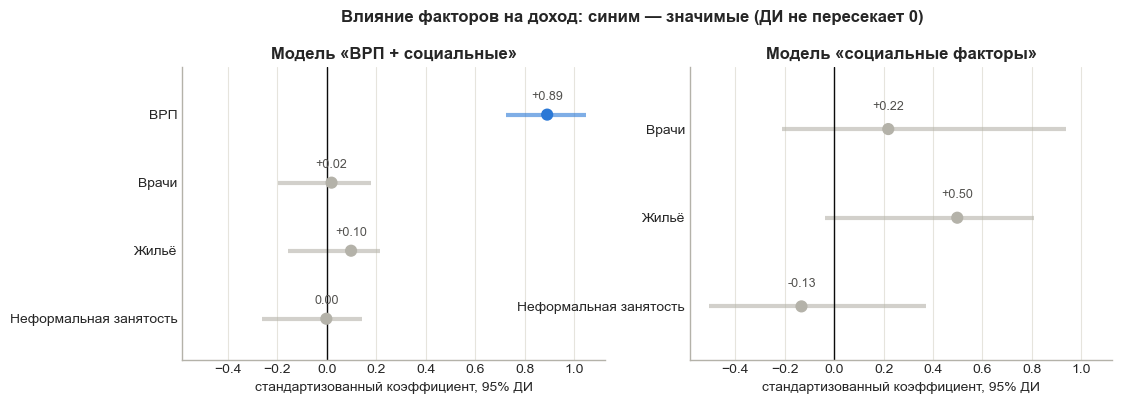

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
for ax, set_name in zip(axes, ["ВРП + социальные", "социальные факторы"]):
    d = coefs[coefs["модель"] == set_name].iloc[::-1]
    yy = np.arange(len(d))
    colors = [BLUE if s == "да" else GRAY for s in d["значим"]]
    ax.hlines(yy, d["95% ДИ от"], d["95% ДИ до"], color=colors, lw=3, alpha=0.6)
    ax.scatter(d["коэф."], yy, color=colors, s=60, zorder=3)
    for yi, v in zip(yy, d["коэф."]):
        ax.text(v, yi + 0.22, f"{v:+.2f}".replace("-0.00", "0.00").replace("+0.00", "0.00"), ha="center", fontsize=9, color=MUTED)
    ax.axvline(0, color=INK, lw=1)
    ax.set_yticks(yy, d["фактор"])
    ax.set_ylim(-0.6, len(d) - 0.3)
    ax.set_title(f"Модель «{set_name}»")
    ax.grid(axis="y", visible=False)
axes[0].set_xlabel("стандартизованный коэффициент, 95% ДИ")
axes[1].set_xlabel("стандартизованный коэффициент, 95% ДИ")
fig.suptitle("Влияние факторов на доход: синим — значимые (ДИ не пересекает 0)", fontweight="bold", y=1.03)
fig.savefig(IMAGES / "13_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=SEED)
cols = FEATURE_SETS["ВРП + социальные"]
rf.fit(D.loc[train, cols], D.y[train])
perm = permutation_importance(rf, D.loc[test, cols], D.y[test], n_repeats=30, random_state=SEED)
pd.DataFrame({"падение R² при перемешивании": perm.importances_mean, "разброс": perm.importances_std},
             index=cols).sort_values("падение R² при перемешивании", ascending=False).round(3)

,падение R² при перемешивании,разброс
ВРП,1.907,0.288
Жильё,0.005,0.004
Неформальная занятость,0.004,0.001
Врачи,0.002,0.003


**Вывод по H1:**
- Когда в модели есть ВРП, **ни врачи, ни жильё, ни неформальная занятость значимо на доход не влияют**: их доверительные интервалы пересекают ноль. Random Forest говорит то же самое: если перемешать ВРП, точность падает многократно, а перемешивание остальных факторов почти ничего не меняет.
- **Без ВРП** самый большой коэффициент у ввода жилья (+0,50), но и он не значим: интервал касается нуля. Социальные факторы объясняют меньше половины разброса и плохо работают на новых регионах. Они скорее отражают богатство региона, чем создают его.
- **H1 подтверждается в части медицины**: связь дохода с обеспеченностью врачами слабая и, при учёте экономики региона, незначимая. Доход определяется экономикой региона. **Проверить роль образования не удалось** — данных по регионам нет (этап 2).
- Неформальная занятость, которая в EDA выглядела растущим фактором отставания, при учёте ВРП значимой не оказалась: регионы с высокой «теневой» занятостью просто беднее по экономике в целом.

<a id="elasticity"></a>
## 7. Эластичность: как богатство региона доходит до людей

В модели «логарифм на логарифм» коэффициент — это **эластичность**: на сколько процентов выше доход, если ВРП на душу выше на 1%.

Эластичность дохода по ВРП: 0.52 (95% ДИ 0.46–0.61), R² = 0.925
→ регион с ВРП на душу вдвое выше имеет доход выше примерно на 44%, а не на 100%


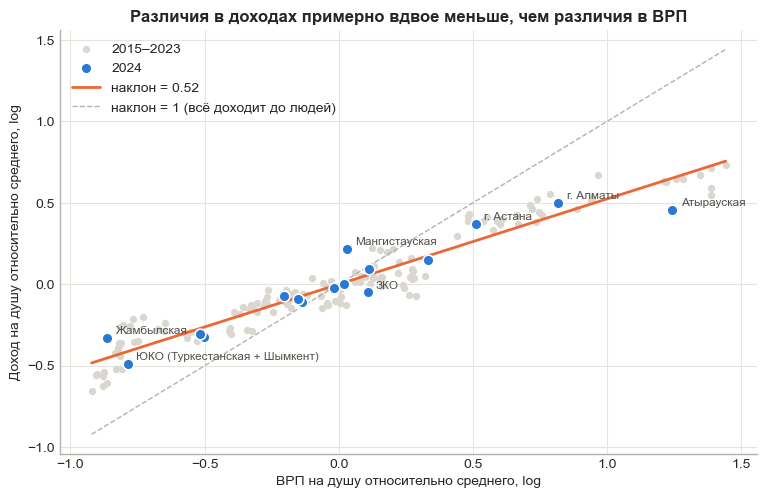

In [9]:
full = LinearRegression().fit(D[["ВРП"]], D.y)
elasticity = full.coef_[0]
lo, hi = np.percentile([LinearRegression().fit(D.iloc[idx][["ВРП"]], D.y.iloc[idx]).coef_[0]
                        for idx in (np.concatenate([index_by_unit[g] for g in rng.choice(groups, len(groups))])
                                    for _ in range(1000))], [2.5, 97.5])
print(f"Эластичность дохода по ВРП: {elasticity:.2f} (95% ДИ {lo:.2f}–{hi:.2f}), R² = {full.score(D[['ВРП']], D.y):.3f}")
print(f"→ регион с ВРП на душу вдвое выше имеет доход выше примерно на {(2 ** elasticity - 1) * 100:.0f}%, а не на 100%")

last = D[D.year == D.year.max()]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(D.ВРП, D.y, s=18, color=LIGHT, zorder=1, label="2015–2023")
ax.scatter(last.ВРП, last.y, s=60, color=BLUE, edgecolor="white", linewidth=1.2, zorder=3, label=f"{int(D.year.max())}")
xs = np.linspace(D.ВРП.min(), D.ВРП.max(), 50)
ax.plot(xs, full.intercept_ + elasticity * xs, color=ORANGE, lw=2, label=f"наклон = {elasticity:.2f}")
ax.plot(xs, xs, color=GRAY, lw=1, ls="--", label="наклон = 1 (всё доходит до людей)")
NOTE = ["Жамбылская", "ЮКО (Туркестанская + Шымкент)", "Мангистауская", "ЗКО", "Атырауская", "г. Астана", "г. Алматы"]
for _, row in last[last.label.isin(NOTE)].iterrows():
    ax.annotate(row.label, (row.ВРП, row.y), xytext=(6, 3), textcoords="offset points", fontsize=8.5, color=MUTED)
ax.set_xlabel("ВРП на душу относительно среднего, log")
ax.set_ylabel("Доход на душу относительно среднего, log")
ax.set_title("Различия в доходах примерно вдвое меньше, чем различия в ВРП")
ax.legend(frameon=False, loc="upper left")
fig.savefig(IMAGES / "14_elasticity.png", dpi=150, bbox_inches="tight")
plt.show()

**Вывод:** эластичность ≈ 0,5. Если экономика региона в расчёте на жителя вдвое больше, доходы населения выше лишь примерно на 44%. Отсюда и разница, которую мы видели в EDA: ВРП на душу различается между регионами в 9,7 раза, а доходы — в 2,8 раза.

Куда уходит остальное — данные не показывают напрямую, но вероятные причины известны: часть ВРП — прибыль компаний и налоги, которые уходят из региона (акционерам, в республиканский бюджет), а доходы бедных регионов подтягиваются трансфертами (пенсии, пособия, бюджетные зарплаты). Для заказчика это означает: **рост экономики региона сам по себе поднимает доходы населения лишь наполовину** — важно, как он распределяется.

<a id="residuals"></a>
## 8. Кто получает больше или меньше, чем «заработал» регион

Остаток модели = фактический доход − доход, который «положен» региону по его ВРП. Положительный остаток — население получает больше, чем предсказывает экономика региона; отрицательный — меньше.

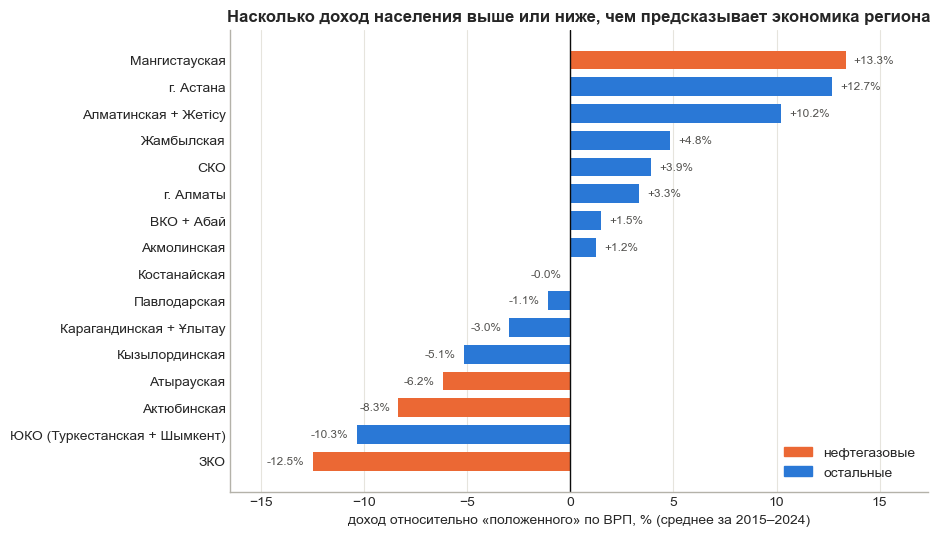

Регионов, у которых знак остатка совпадает в 9–10 годах из 10: 9 из 16


In [10]:
D["остаток"] = D.y - full.predict(D[["ВРП"]])
res = (D.groupby("label")["остаток"].agg(["mean", "std"])
       .assign(pct=lambda t: (np.exp(t["mean"]) - 1) * 100)
       .sort_values("pct"))
oil = set(units.loc[units.is_resource, "label"])

fig, ax = plt.subplots(figsize=(9, 6))
colors = [ORANGE if name in oil else BLUE for name in res.index]
ax.barh(res.index, res.pct, color=colors, height=0.7)
for yi, (v, sd) in enumerate(zip(res.pct, res["std"])):
    ax.text(v + (0.4 if v >= 0 else -0.4), yi, f"{v:+.1f}%", va="center", ha="left" if v >= 0 else "right",
            fontsize=8.5, color=MUTED)
ax.axvline(0, color=INK, lw=1)
ax.set_xlim(res.pct.min() - 4, res.pct.max() + 4)
ax.set_xlabel("доход относительно «положенного» по ВРП, % (среднее за 2015–2024)")
ax.set_title("Насколько доход населения выше или ниже, чем предсказывает экономика региона")
ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ORANGE), plt.Rectangle((0, 0), 1, 1, color=BLUE)],
          labels=["нефтегазовые", "остальные"], frameon=False, loc="lower right")
fig.savefig(IMAGES / "15_residuals.png", dpi=150, bbox_inches="tight")
plt.show()

stable = (D.assign(sign=np.sign(D["остаток"])).groupby("label").sign.apply(lambda s: (s == s.mode()[0]).mean()))
print(f"Регионов, у которых знак остатка совпадает в 9–10 годах из 10: {(stable >= 0.9).sum()} из {len(stable)}")

**Вывод:** у регионов с крупными остатками знак почти не меняется из года в год: ЗКО, ЮКО, Актюбинская, Мангистауская и Астана — 10 лет из 10, Атырауская — 9 из 10. Это не шум, а устойчивые особенности. Знак «прыгает» только у регионов с остатком около нуля (Павлодарская, Костанайская), что и ожидаемо.
- **Получают меньше, чем «заработали»: ЗКО (−12%), ЮКО (−10%), Актюбинская (−8%), Атырауская (−6%).** Три из четырёх — нефтегазовые. Вероятное объяснение: высокий ВРП создаёт добыча, а её прибыль и налоги уходят из региона — акционерам и в республиканский бюджет.
- **Получают больше: Мангистауская (+13%), Астана (+13%), Алматинская + Жетісу (+10%).** Для Астаны правдоподобное объяснение — концентрация госуправления и бюджетных зарплат. Почему Мангистауская, тоже нефтяная, ведёт себя противоположно Атырау и ЗКО, по этим данным не установить: для ответа нужны данные о структуре занятости и зарплат по отраслям.

Для заказчика это готовый список вопросов: почему в ЗКО и Атырау богатство экономики доходит до населения хуже, чем в Мангистауской области?

<a id="summary"></a>
## 9. Выводы этапа

1. **Доход региона почти полностью объясняется его экономикой.** Линейная регрессия на одном ВРП на душу объясняет 89–90% различий и предсказывает доход в новых годах и новых регионах с ошибкой 7–8%. Более сложные модели (больше факторов, Random Forest) точнее не становятся — только переобучаются.
2. **H1 подтверждается в части медицины:** при учёте ВРП обеспеченность врачами на доход значимо не влияет. Роль образования проверить не удалось — нет данных по регионам.
3. **Богатство доходит до людей наполовину:** эластичность дохода по ВРП ≈ 0,5. Рост экономики региона вдвое поднимает доходы лишь примерно на 44%.
4. **Нефтегазовые ЗКО, Атырауская и Актюбинская устойчиво недополучают** 6–12% дохода относительно своей экономики, а Мангистауская и Астана — получают больше на 13%.

**Ограничения:** модель показывает связь, а не причину; ВРП и доход отчасти измеряют одно и то же (зарплаты входят в ВРП); 16 единиц — маленькая выборка, поэтому выводы о слабых факторах осторожные: «значимой связи не найдено», а не «связи нет».